# Improving Recognition of Rare Postural Transitions

**Question.** Why do six standard classifiers recognise the six common activities well but struggle with the six rare transitions, and which change helps most?

**The experiment follows one chain:** (1) establish single-window baselines; (2) compare a previous window, three-window context, mild class weighting and random oversampling; (3) extend the full past/future context; (4) find a practical window length for each model; (5) test whether PCA saves computation; and (6) compare the resulting configurations. The primary metric is **macro-F1 over transition classes 7–12**. Common-activity macro-F1, all-class macro-F1, accuracy and runtime are supporting measures.

Window counts are chosen from participant-grouped validation on the original 21 training participants. The nine test participants were already inspected during development, so their scores are **descriptive rather than untouched final estimates**. Future-window features also make this an **offline** method. The recorded tables keep the story readable without rerunning every expensive fit; the executable comparisons remain below.

## Experimental setup

Each row is a 2.56-second sensor window with 561 engineered features. Participant and activity columns are metadata, never predictors. We retain the original train/test participant split and use three-fold `StratifiedGroupKFold` (seed 42) within the training participants. Scaling, PCA and oversampling are fitted or applied inside each training fold. Logistic regression also has a repeated validation with three split seeds.

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
THREAD_LIMITS = threadpool_limits(limits=2)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

DATA_DIR = Path.cwd() / "wrangled data"
if not (DATA_DIR / "hapt_train.csv").exists():
    DATA_DIR = Path.cwd() / "our approach" / "wrangled data"
if not (DATA_DIR / "hapt_train.csv").exists():
    raise FileNotFoundError("Run from the notebook folder or the project root")

train_df = pd.read_csv(DATA_DIR / "hapt_train.csv")
test_df = pd.read_csv(DATA_DIR / "hapt_test.csv")
META_COLUMNS = ["subject_id", "activity_id", "activity_label"]
FEATURE_COLUMNS = [c for c in train_df.columns if c not in META_COLUMNS]
LABELS = np.arange(1, 13)
TRANSITION_LABELS = np.arange(7, 13)

assert len(FEATURE_COLUMNS) == 561
assert set(test_df.columns) == set(train_df.columns)
print(f"Train: {train_df.shape}; test: {test_df.shape}; features: {len(FEATURE_COLUMNS)}")
print(f"Train participants: {train_df.subject_id.nunique()}; test participants: {test_df.subject_id.nunique()}")
print(f"Participant overlap: {set(train_df.subject_id) & set(test_df.subject_id)}")
train_class_counts = train_df.groupby(["activity_id", "activity_label"]).size().rename("windows")
test_class_counts = test_df.groupby(["activity_id", "activity_label"]).size().rename("windows")
display(pd.concat({"train": train_class_counts, "test": test_class_counts}, axis=1).fillna(0).astype(int))

Train: (7767, 564); test: (3162, 564); features: 561
Train participants: 21; test participants: 9
Participant overlap: set()


,,train,test
activity_id,activity_label,,
1,WALKING,1226,496
2,WALKING_UPSTAIRS,1073,471
3,WALKING_DOWNSTAIRS,987,420
4,SITTING,1293,508
5,STANDING,1423,556
6,LAYING,1413,545
7,STAND_TO_SIT,47,23
8,SIT_TO_STAND,23,10
9,SIT_TO_LIE,75,32


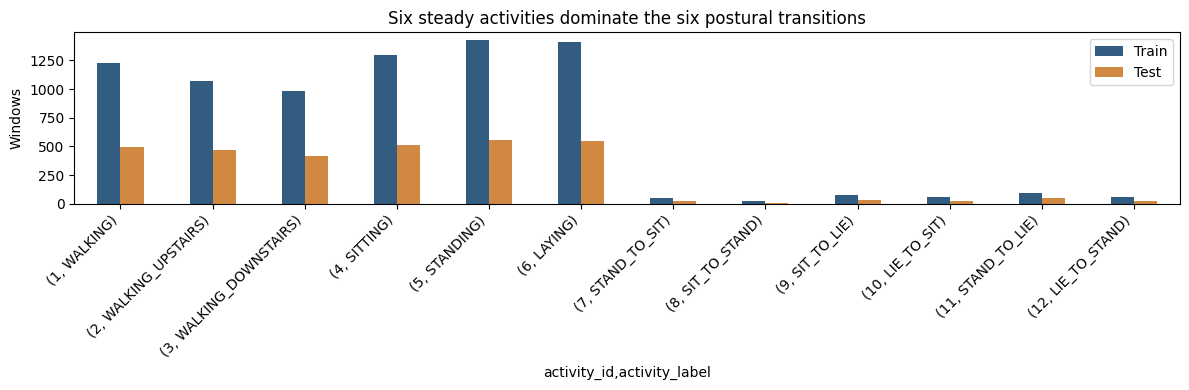

In [2]:
import matplotlib.pyplot as plt
class_counts = pd.concat({"Train": train_class_counts, "Test": test_class_counts}, axis=1)
ax = class_counts.plot.bar(figsize=(12, 4), color=["#335c81", "#d08842"])
ax.set_ylabel("Windows")
ax.set_title("Six steady activities dominate the six postural transitions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### How neighbouring windows become features

A previous-only input contains the current window and all 561 features from the preceding window. A symmetric three-window input contains the complete previous, current and following windows. Longer odd-numbered inputs extend equally into the past and future. At participant boundaries, the edge row is repeated. The CSVs do not identify every recording boundary *within* a participant, which limits interpretation of long context.

In [3]:
def arrays(frame):
    x = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    y = frame.activity_id.to_numpy(dtype=np.int64)
    groups = frame.subject_id.to_numpy(dtype=np.int64)
    return x, y, groups


def add_context(x, groups, mode="single"):
    if mode == "single":
        offsets = (0,)
    elif mode == "previous":
        offsets = (-1, 0)
    elif mode == "bidirectional":
        offsets = (-1, 0, 1)
    elif isinstance(mode, int) and mode > 0 and mode % 2 == 1:
        offsets = tuple(range(-(mode // 2), mode // 2 + 1))
    else:
        raise ValueError(f"Unknown context: {mode}")
    starts = np.r_[0, np.flatnonzero(groups[1:] != groups[:-1]) + 1]
    ends = np.r_[starts[1:] - 1, len(groups) - 1]
    first = np.repeat(starts, ends - starts + 1)
    last = np.repeat(ends, ends - starts + 1)
    row = np.arange(len(x))
    return np.hstack([x[np.clip(row + offset, first, last)] for offset in offsets])

def class_weights(y, exponent=0.5):
    counts = np.bincount(y, minlength=13)
    sample_weight = counts[y].astype(float) ** (-exponent)
    return sample_weight / sample_weight.mean()


def oversample_indices(y, target, seed=42):
    rng = np.random.default_rng(seed)
    indices = [np.arange(len(y))]
    for label in TRANSITION_LABELS:
        found = np.flatnonzero(y == label)
        if len(found) < target:
            indices.append(rng.choice(found, size=target - len(found), replace=True))
    return np.concatenate(indices)


def scores(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    return {
        "transition_f1": float(f1[6:].mean()),
        "transition_recall": float(recall[6:].mean()),
        "common_f1": float(f1[:6].mean()),
        "macro_f1": float(f1.mean()),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "per_class_f1": f1,
        "per_class_recall": recall,
        "per_class_precision": precision,
        "support": support,
    }

x_train, y_train, groups_train = arrays(train_df)
x_test, y_test, groups_test = arrays(test_df)
assert set(groups_train).isdisjoint(groups_test)
assert len(np.unique(groups_train)) == 1 + np.count_nonzero(groups_train[1:] != groups_train[:-1])
assert len(np.unique(groups_test)) == 1 + np.count_nonzero(groups_test[1:] != groups_test[:-1])
print("Context feature counts:", {m: add_context(x_train[:3], np.repeat(1, 3), m).shape[1] for m in ["single", "previous", "bidirectional"]})

Context feature counts: {'single': 561, 'previous': 1122, 'bidirectional': 1683}


In [4]:
# Boundary check: neighbour features must never come from another participant.
toy_x = np.arange(4, dtype=np.float32).reshape(-1, 1)
toy_groups = np.array([1, 1, 2, 2])
assert add_context(toy_x, toy_groups, 3).tolist() == [
    [0, 0, 1], [0, 1, 1], [2, 2, 3], [2, 3, 3]]
assert add_context(toy_x, toy_groups, "previous").tolist() == [
    [0, 0], [0, 1], [2, 2], [2, 3]]

### Six fixed model families

We compare logistic regression, linear SVM, random forest, XGBoost, an MLP and shrinkage LDA on the same participant-grouped folds. Settings within each model stay fixed as context, weighting or sampling changes. The MLP trains for 15 epochs; its loss uses sample weights when that condition calls for them. Its eight-window posture-memory prediction rule is fixed in every run, including the baseline. Thus the MLP baseline is a comparison without added context or class balancing, but it is not a wholly untreated transition predictor.

Shrinkage LDA uses `lsqr`, automatic shrinkage and equal class priors (`1/12`
each). Its calls use `weight_exponent=0` because priors differ from sample
weighting. The `lda_memory` option defaults to `False`; enabling it applies
the same fixed posture-memory rule.

In [5]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC


def prepare(x_train, x_eval, representation="raw"):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(x_train)
    eval_scaled = scaler.transform(x_eval)
    if representation.startswith("pca"):
        pca = PCA(n_components=int(representation[3:]), svd_solver="randomized", random_state=42)
        train_scaled = pca.fit_transform(train_scaled)
        eval_scaled = pca.transform(eval_scaled)
    return train_scaled.astype(np.float32), eval_scaled.astype(np.float32)


def posture_memory(probabilities, groups):
    prediction = probabilities.argmax(axis=1)
    start = 0
    for row in range(len(prediction)):
        if row == 0 or groups[row] != groups[row - 1]:
            start = row
        if prediction[row] not in (8, 10):
            continue
        mass = probabilities[row, [8, 10]].sum()
        score = probabilities[row, 10] / mass if mass else 0.5
        past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
        if past.sum() >= 0.75:
            score = past[1] / past.sum()
        prediction[row] = 10 if score > 0.5 else 8
    return prediction + 1


def mlp_predict(x_train, y_train, sample_weight, x_eval, eval_groups, epochs=15):
    import torch
    import torch.nn.functional as F
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset

    torch.set_num_threads(1)
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Linear(x_train.shape[1], 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 12),
    )
    for layer in model:
        if isinstance(layer, nn.Linear):
            if layer.out_features == 12:
                nn.init.xavier_uniform_(layer.weight)
            else:
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    if sample_weight is None:
        sample_weight = np.ones(len(y_train), dtype=np.float32)
    data = TensorDataset(
        torch.from_numpy(x_train),
        torch.from_numpy((y_train - 1).astype(np.int64)),
        torch.from_numpy(sample_weight.astype(np.float32)),
    )
    loader = DataLoader(data, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)
    model.train()
    for _ in range(epochs):
        for batch_x, batch_y, batch_weight in loader:
            optimizer.zero_grad()
            losses = F.cross_entropy(model(batch_x), batch_y, reduction="none")
            loss = (losses * batch_weight).sum() / batch_weight.sum()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        probabilities = model(torch.from_numpy(x_eval)).softmax(dim=1).numpy()
    return posture_memory(probabilities, eval_groups)


def predict(model_name, x_train, y_train, x_eval, sample_weight=None,
            eval_groups=None, epochs=15, lda_memory=False):
    if model_name == "lda":
        if sample_weight is not None:
            raise ValueError("LDA uses equal priors and does not accept sample_weight.")
        model = LinearDiscriminantAnalysis(
            solver="lsqr", shrinkage="auto", priors=np.full(12, 1 / 12))
        model.fit(x_train, y_train)
        if lda_memory:
            if eval_groups is None or len(eval_groups) != len(x_eval):
                raise ValueError("LDA memory needs one participant ID per evaluation row.")
            np.testing.assert_array_equal(model.classes_, LABELS)
            return posture_memory(model.predict_proba(x_eval), eval_groups)
        return model.predict(x_eval)
    if model_name == "mlp":
        return mlp_predict(x_train, y_train, sample_weight, x_eval, eval_groups, epochs)
    if model_name == "logreg":
        model = LogisticRegression(C=0.1, solver="lbfgs", max_iter=600)
    elif model_name == "linear_svm":
        model = LinearSVC(C=0.01, dual=False, max_iter=2000)
    elif model_name == "random_forest":
        model = RandomForestClassifier(n_estimators=200, n_jobs=2, random_state=42)
    elif model_name == "xgboost":
        from xgboost import XGBClassifier
        model = XGBClassifier(
            objective="multi:softprob", num_class=12, tree_method="hist", n_jobs=2,
            n_estimators=300, max_depth=6, learning_rate=0.138,
            subsample=0.616, colsample_bytree=0.847, gamma=0.00075,
            min_child_weight=7, random_state=42,
        )
        model.fit(x_train, y_train - 1, sample_weight=sample_weight)
        return model.predict(x_eval) + 1
    else:
        raise ValueError(model_name)
    model.fit(x_train, y_train, sample_weight=sample_weight)
    return model.predict(x_eval)

def evaluate_cv(model_name="logreg", context="bidirectional", weight_exponent=0.5,
                oversample_target=0, representation="raw", epochs=15, seed=42,
                lda_memory=False):
    if model_name == "lda" and weight_exponent != 0:
        raise ValueError("For LDA, set weight_exponent=0; equal class priors are used instead.")
    features = add_context(x_train, groups_train, context)
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    from time import perf_counter
    rows = []
    for fold, (tr, va) in enumerate(splitter.split(features, y_train, groups_train), 1):
        assert set(groups_train[tr]).isdisjoint(groups_train[va])
        fold_x, fold_y = features[tr], y_train[tr]
        sample_weight = class_weights(fold_y, weight_exponent) if weight_exponent else None
        if oversample_target:
            idx = oversample_indices(fold_y, oversample_target, seed=42 + fold)
            fold_x, fold_y = fold_x[idx], fold_y[idx]
            if sample_weight is not None:
                sample_weight = sample_weight[idx]
        started = perf_counter()
        fit_x, val_x = prepare(fold_x, features[va], representation)
        pred = predict(model_name, fit_x, fold_y, val_x, sample_weight, groups_train[va], epochs,
                       lda_memory=lda_memory)
        rows.append({"fold": fold, "elapsed_seconds": perf_counter() - started, **scores(y_train[va], pred)})
    return pd.DataFrame(rows)


def evaluate_test(model_name="logreg", context="bidirectional", weight_exponent=0.5,
                  oversample_target=0, representation="raw", epochs=15,
                  lda_memory=False):
    if model_name == "lda" and weight_exponent != 0:
        raise ValueError("For LDA, set weight_exponent=0; equal class priors are used instead.")
    train_features = add_context(x_train, groups_train, context)
    test_features = add_context(x_test, groups_test, context)
    fit_y = y_train.copy()
    sample_weight = class_weights(fit_y, weight_exponent) if weight_exponent else None
    if oversample_target:
        idx = oversample_indices(fit_y, oversample_target, seed=42)
        train_features, fit_y = train_features[idx], fit_y[idx]
        if sample_weight is not None:
            sample_weight = sample_weight[idx]
    fit_x, eval_x = prepare(train_features, test_features, representation)
    pred = predict(model_name, fit_x, fit_y, eval_x, sample_weight, groups_test, epochs,
                   lda_memory=lda_memory)
    result = scores(y_test, pred)
    result["predictions"] = pred
    return result

# Example reruns (not executed automatically):
# evaluate_cv("logreg", context="bidirectional", weight_exponent=0.5)
# evaluate_test("random_forest", context="bidirectional", weight_exponent=0.5, oversample_target=60)

## 1. Initial attempt: change the model, keep one window

First, each model sees only the current window, with no added class weights or oversampling. The table below reports grouped-validation transition macro-F1. The separate test table then shows the central problem directly: common activities are already recognised well, while transition F1 is much lower. Changing model family alone does not remove that gap. The MLP retains the fixed posture-memory rule described above. LDA retains equal class priors, with posture memory disabled for this baseline.

In [6]:
models = ["Logistic regression", "Linear SVM", "Random forest", "XGBoost", "MLP (15 epochs + memory)", "Shrinkage LDA"]
# Recorded LDA validation results; training code is in the companion notebook.
lda_baseline_cv = pd.DataFrame([
    (1, 0.7049376352490268),
    (2, 0.7741547534212708),
    (3, 0.7910014324160194),
], columns=['fold', 'transition_f1'])
lda_three_cv = pd.DataFrame([
    (1, 0.8564632680756022, 0.9314653932734115, 10.0943328),
    (2, 0.8992987985773779, 0.937913585065442, 9.4598964),
    (3, 0.9192516769969531, 0.9388895668299874, 8.7027863),
], columns=['fold', 'transition_f1', 'common_f1', 'elapsed_seconds'])
validation_ablation = pd.DataFrame({
    "Model": models,
    "Baseline": [0.7433, 0.7367, 0.6411, 0.6774, 0.7413, lda_baseline_cv.transition_f1.mean()],
    "Weights only": [0.7385, 0.7451, 0.6787, 0.7561, 0.7577, np.nan],
    "Three windows only": [0.8540, 0.8503, 0.8131, 0.7954, 0.8981, lda_three_cv.transition_f1.mean()],
    "Three windows + weights": [0.8631, 0.8649, 0.8236, 0.8398, 0.8661, np.nan],
})
validation_display = validation_ablation.round(4).astype(object)
lda_row = validation_display["Model"] == "Shrinkage LDA"
validation_display.loc[lda_row, ["Weights only", "Three windows + weights"]] = "Not applicable"
validation_display

,Model,Baseline,Weights only,Three windows only,Three windows + weights
0,Logistic regression,0.7433,0.7385,0.854,0.8631
1,Linear SVM,0.7367,0.7451,0.8503,0.8649
2,Random forest,0.6411,0.6787,0.8131,0.8236
3,XGBoost,0.6774,0.7561,0.7954,0.8398
4,MLP (15 epochs + memory),0.7413,0.7577,0.8981,0.8661
5,Shrinkage LDA,0.7567,Not applicable,0.8917,Not applicable


**Descriptive single-window test check.** Common-class macro-F1 is 0.9207–0.9562 across the six evaluated models, while the six-transition macro-F1 is much lower. This is the initial performance gap; the test set was not untouched during development.

| Model | Test common F1 | Test transition F1 | Test accuracy |
|---|---:|---:|---:|
| Logistic regression | 0.9514 | 0.7532 | 0.9386 |
| Linear SVM | 0.9562 | 0.8112 | 0.9459 |
| XGBoost | 0.9437 | 0.7888 | 0.9358 |
| Random forest | 0.9207 | 0.7120 | 0.9105 |
| MLP + posture memory | 0.9477 | 0.8607 | 0.9443 |
| Shrinkage LDA | 0.9491 | 0.7829 | 0.9399 |

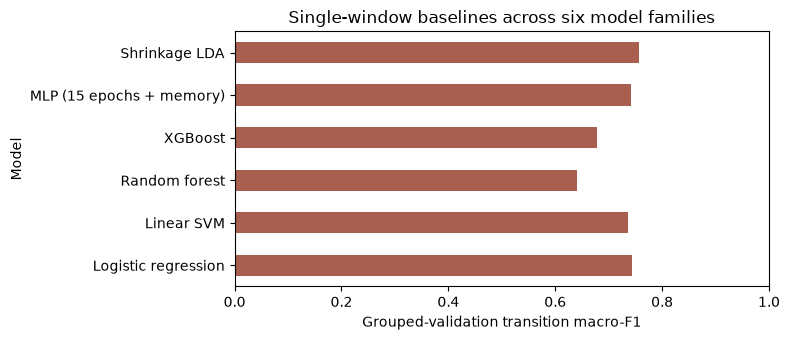

In [7]:
baseline_plot = validation_ablation.set_index("Model")["Baseline"]
ax = baseline_plot.plot.barh(figsize=(8, 3.5), color="#a95f4f")
ax.set_xlim(0, 1)
ax.set_xlabel("Grouped-validation transition macro-F1")
ax.set_title("Single-window baselines across six model families")
plt.tight_layout()
plt.show()

## 2. Compare four ways to help rare transitions

We tested four concrete changes against the single-window baseline:

1. **Previous window:** append all features from the preceding window. This direct check is recorded for logistic regression and shrinkage LDA.
2. **Three-window context:** append all features from both the preceding and following windows. This is the main temporal comparison across all six models.
3. **Mild class weighting:** use inverse square-root class-frequency weights within each training fold for logistic regression, linear SVM, random forest, XGBoost and MLP. LDA uses equal class priors.
4. **Random oversampling (ROS):** duplicate rare-class training rows inside each fold; this is tested after three-window context with each model's imbalance treatment fixed.

The earlier ablation table separates weighting and three-window context. The previous-only and oversampling results appear next.

In [8]:
past_only_folds = pd.DataFrame({
    "Fold": [1, 2, 3],
    "Transition F1": [0.7660968661, 0.7657879713, 0.7603960604],
    "Common F1": [0.9438038431, 0.9441629064, 0.8885234726],
})
display(past_only_folds.round(4))
print("Past-only logistic regression, mean grouped-validation transition F1:",
      round(past_only_folds["Transition F1"].mean(), 4))

# Common-F1 fold values retain the four decimals saved in the recorded output.
lda_previous_cv = pd.DataFrame([
    (1, 0.7520312514960037, 0.9308),
    (2, 0.7834419381787803, 0.9375),
    (3, 0.8079317911347701, 0.9372),
], columns=['fold', 'transition_f1', 'common_f1'])
print("Past-only LDA, mean grouped-validation transition F1:",
      round(lda_previous_cv.transition_f1.mean(), 4))
display(lda_previous_cv[["fold", "transition_f1", "common_f1"]].round(4))

,Fold,Transition F1,Common F1
0,1,0.7661,0.9438
1,2,0.7658,0.9442
2,3,0.7604,0.8885


Past-only logistic regression, mean grouped-validation transition F1: 0.7641


Past-only LDA, mean grouped-validation transition F1: 0.7811


,fold,transition_f1,common_f1
0,1,0.7520,0.9308
1,2,0.7834,0.9375
2,3,0.8079,0.9372


In [9]:
# A small direct check of the past-only idea, using the same three grouped folds.
# Set this to True to rerun four logistic-regression fits (CV + descriptive test).
RUN_PREVIOUS_WINDOW = False
if RUN_PREVIOUS_WINDOW:
    previous_cv = evaluate_cv("logreg", context="previous", weight_exponent=0)
    previous_test = evaluate_test("logreg", context="previous", weight_exponent=0)
    display(previous_cv[["fold", "transition_f1", "common_f1"]])
    print("Mean CV transition F1:", previous_cv.transition_f1.mean())
    print("Descriptive test transition F1:", previous_test["transition_f1"])
else:
    print("Past-only logistic regression is available above; enable RUN_PREVIOUS_WINDOW to rerun it.")

Past-only logistic regression is available above; enable RUN_PREVIOUS_WINDOW to rerun it.


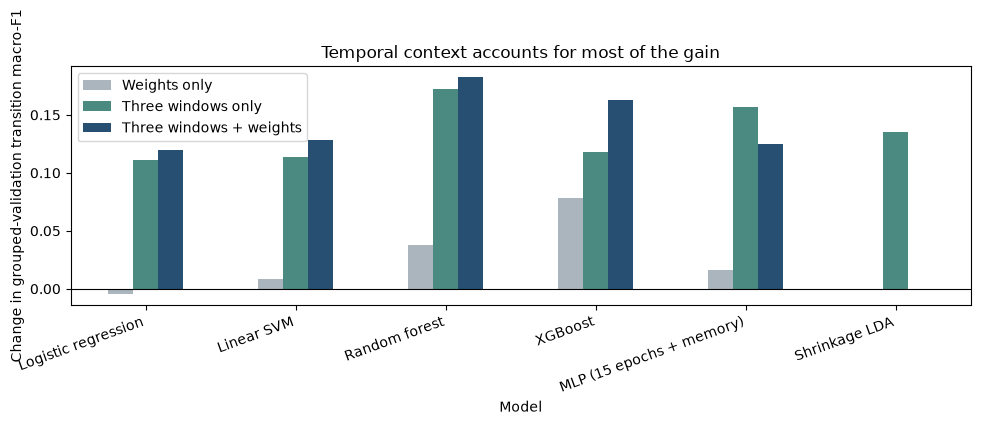

In [10]:
ablation_delta = validation_ablation.set_index("Model").drop(columns="Baseline").sub(
    validation_ablation.set_index("Model")["Baseline"], axis=0)
ax = ablation_delta.plot.bar(figsize=(10, 4), color=["#aab5bd", "#4b8a80", "#264f71"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Change in grouped-validation transition macro-F1")
ax.set_title("Temporal context accounts for most of the gain")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**The decisive change is complete three-window context.** Across the five classifiers in the weighting comparison, mean transition F1 rises from **0.708** at baseline to **0.842** with three windows alone. Weighting alone reaches **0.735**. For logistic regression, adding only the previous full window reaches **0.764**, compared with **0.743** at baseline and **0.854** with both neighbours. Combining three windows with weighting reaches a mean of **0.852**, although it *reduces* the MLP score relative to three windows alone. In the descriptive test comparison below, all six models also improve common-class F1 by 0.0040–0.0192, so the transition gain does not come at a measured common-class cost in this matched comparison.

For shrinkage LDA with equal priors and memory off, mean transition F1 is **0.7567** with one window, **0.7811** with previous/current input and **0.8917** with three windows. Three-window context improves transition F1 in **3/3 folds**, with a mean change of **+0.1350**. Common-class F1 changes from **0.9264** to **0.9361**. LDA's weighting cells are not applicable, so it is excluded from the five-model weighting averages above.

**What three full windows changed on the test set.** These are the unweighted, non-oversampled three-window fits compared with the single-window fits above. Positive values mean improvement; common-class changes are shown explicitly rather than assumed to be zero. LDA retains equal priors in both fits, with posture memory off.

| Model | Transition F1 change | Common F1 change |
|---|---:|---:|
| Logistic regression | +0.1513 | +0.0043 |
| Linear SVM | +0.0706 | +0.0132 |
| XGBoost | +0.0965 | +0.0136 |
| Random forest | +0.1597 | +0.0040 |
| MLP + posture memory | +0.0644 | +0.0129 |
| Shrinkage LDA | +0.1163 | +0.0192 |

### 2.4 Random oversampling as a follow-up

We duplicate transition-class training rows until each rare class has at least 60 or 100 rows in a fold. Validation rows keep their natural prevalence. This tests whether resampling adds anything after three-window context and mild weighting. LDA retains equal priors instead of sample weights, with posture memory disabled.

In [11]:
# Recorded LDA oversampling validation results.
lda_ros60_cv = pd.DataFrame([
    (1, 0.8537636374987337),
    (2, 0.8842375605767159),
    (3, 0.9301353617143091),
], columns=['fold', 'transition_f1'])
lda_ros100_cv = pd.DataFrame([
    (1, 0.8435074943129267),
    (2, 0.8907389892942007),
    (3, 0.9301353617143091),
], columns=['fold', 'transition_f1'])
oversampling = pd.DataFrame({
    "Model": models,
    "No ROS": [0.8631, 0.8649, 0.8236, 0.8398, 0.8661, lda_three_cv.transition_f1.mean()],
    "ROS target 60": [0.8641, 0.8669, 0.8373, 0.8359, 0.8985, lda_ros60_cv.transition_f1.mean()],
    "ROS target 100": [0.8668, 0.8655, 0.8231, 0.8192, 0.8868, lda_ros100_cv.transition_f1.mean()],
})
display(oversampling.round(4))
rf_ros_confirmation = pd.DataFrame({
    "Fold seed": [42, 123, 2026, "All nine paired folds"],
    "No ROS transition F1": [0.8236, 0.8576, 0.8238, 0.8350],
    "ROS 60 transition F1": [0.8373, 0.8613, 0.8367, 0.8451],
    "Common F1 change": [-0.0026, -0.0041, -0.0020, -0.0029],
})
display(rf_ros_confirmation.round(4))

,Model,No ROS,ROS target 60,ROS target 100
0,Logistic regression,0.8631,0.8641,0.8668
1,Linear SVM,0.8649,0.8669,0.8655
2,Random forest,0.8236,0.8373,0.8231
3,XGBoost,0.8398,0.8359,0.8192
4,MLP (15 epochs + memory),0.8661,0.8985,0.8868
5,Shrinkage LDA,0.8917,0.8894,0.8881


,Fold seed,No ROS transition F1,ROS 60 transition F1,Common F1 change
0,42,0.8236,0.8373,-0.0026
1,123,0.8576,0.8613,-0.0041
2,2026,0.8238,0.8367,-0.0020
3,All nine paired folds,0.8350,0.8451,-0.0029


ROS-60 adds little for logistic regression and SVM, gives mixed results for XGBoost, and raises random-forest transition F1 by about **0.010** over nine paired folds with a small common-class decline. It raises the MLP three-fold score from **0.8661** to **0.8985**, so calling all three alternatives “trivial” would overstate the result. ROS-100 does not consistently improve on ROS-60. The next sweep uses no oversampling and keeps each classifier's stated imbalance treatment fixed.

For three-window LDA, mean transition F1 is **0.8917** without ROS, **0.8894** with ROS-60 and **0.8881** with ROS-100. Corresponding common-class F1 scores are **0.9361**, **0.9379** and **0.9385**. Neither ROS target improves mean transition F1 in this three-fold check.

## 3. Extend complete past and future context

Three windows suggest that transitions need temporal context, so we next add complete pairs of earlier and later windows: 5, 7, 9 and beyond. Each point below uses the same seed-42 participant-grouped folds, model settings and raw features. LDA uses equal priors, while the other classifiers use mild sample weighting. No oversampling is used, and LDA memory is off. All six models improve from three to five windows, although later curves are not monotonic. This tests how far the temporal benefit continues before choosing a practical length.

For LDA with memory off, the highest measured transition F1 in this sweep is **0.9560** at **9 windows**, compared with **0.8917** at three windows. The eleven-window input contains **6,171 features** and averages **204.9 seconds per fold** in this run. Timings depend on the machine and workload.

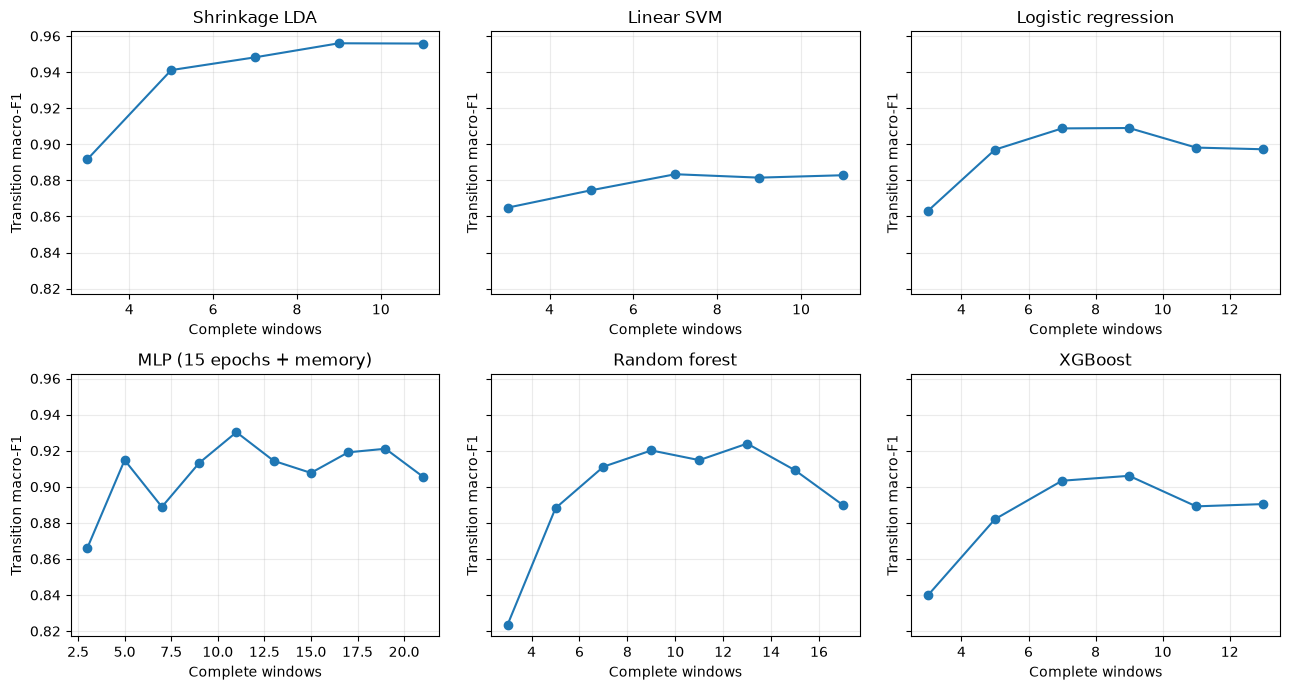

window,3,5,7,9,11,13,15,17,19,21
model,,,,,,,,,,
Shrinkage LDA,0.8917,0.9411,0.9482,0.9560,0.9558,NaN,NaN,NaN,NaN,NaN
Linear SVM,0.8649,0.8745,0.8834,0.8815,0.8828,NaN,NaN,NaN,NaN,NaN
Logistic regression,0.8631,0.8970,0.9088,0.9090,0.8981,0.8972,NaN,NaN,NaN,NaN
MLP (15 epochs + memory),0.8661,0.9148,0.8888,0.9132,0.9302,0.9144,0.9077,0.9191,0.9211,0.9057
Random forest,0.8236,0.8881,0.9111,0.9201,0.9148,0.9239,0.9091,0.8898,NaN,NaN
XGBoost,0.8398,0.8820,0.9033,0.9061,0.8891,0.8904,NaN,NaN,NaN,NaN


LDA window-length validation and runtime (memory off):


,window,features,transition_f1,common_f1,mean_seconds_per_fold
0,3,1683,0.8917,0.9361,9.4190
1,5,2805,0.9411,0.9393,22.0697
2,7,3927,0.9482,0.9469,52.0453
3,9,5049,0.9560,0.9521,95.6886
4,11,6171,0.9558,0.9525,204.8740


In [12]:
recorded_window_cv = pd.DataFrame([('logreg', 3, 0.863066, 0.929754),
 ('logreg', 5, 0.897008, 0.934126),
 ('logreg', 7, 0.908785, 0.941388),
 ('logreg', 9, 0.909004, 0.949199),
 ('logreg', 11, 0.898146, 0.956892),
 ('logreg', 13, 0.897223, 0.960436),
 ('linear_svm', 3, 0.86486, 0.93827),
 ('linear_svm', 5, 0.874533, 0.941788),
 ('linear_svm', 7, 0.883384, 0.944815),
 ('linear_svm', 9, 0.881498, 0.94952),
 ('linear_svm', 11, 0.882827, 0.953759),
 ('random_forest', 3, 0.823618, 0.902745),
 ('random_forest', 5, 0.888143, 0.90347),
 ('random_forest', 7, 0.911125, 0.910286),
 ('random_forest', 9, 0.920133, 0.915836),
 ('random_forest', 11, 0.914753, 0.923796),
 ('random_forest', 13, 0.92392, 0.926642),
 ('random_forest', 15, 0.90913, 0.933219),
 ('random_forest', 17, 0.889838, 0.937963),
 ('xgboost', 3, 0.839825, 0.919538),
 ('xgboost', 5, 0.882031, 0.925457),
 ('xgboost', 7, 0.903337, 0.931203),
 ('xgboost', 9, 0.906057, 0.941327),
 ('xgboost', 11, 0.889135, 0.946838),
 ('xgboost', 13, 0.890391, 0.952107),
 ('mlp', 3, 0.866119, 0.92395),
 ('mlp', 5, 0.914771, 0.924389),
 ('mlp', 7, 0.888835, 0.934704),
 ('mlp', 9, 0.913176, 0.937444),
 ('mlp', 11, 0.930245, 0.932897),
 ('mlp', 13, 0.914375, 0.946619),
 ('mlp', 15, 0.907673, 0.946966),
 ('mlp', 17, 0.919084, 0.943504),
 ('mlp', 19, 0.921063, 0.952612),
 ('mlp', 21, 0.905676, 0.944787)], columns=['model', 'window', 'transition_f1', 'common_f1'])
# Recorded LDA fold scores and measured runtimes (memory off).
lda_window_folds = {3: lda_three_cv}
lda_window_folds[5] = pd.DataFrame([
    (1, 0.9236464810568004, 0.9416198962078403, 26.3931997999),
    (2, 0.945380032438856, 0.9403373269222638, 13.6839702),
    (3, 0.9542799738342213, 0.9360438225892671, 26.1319158),
], columns=['fold', 'transition_f1', 'common_f1', 'elapsed_seconds'])
lda_window_folds[7] = pd.DataFrame([
    (1, 0.9326608551882543, 0.9554976923375288, 75.4874012),
    (2, 0.9464983726284036, 0.9475876862419591, 43.1111689999),
    (3, 0.9653910849453323, 0.9376002710222787, 37.5374135),
], columns=['fold', 'transition_f1', 'common_f1', 'elapsed_seconds'])
lda_window_folds[9] = pd.DataFrame([
    (1, 0.9494984402943367, 0.9694772292432288, 137.0812905),
    (2, 0.9530221780867262, 0.9511441944559218, 77.9315242),
    (3, 0.9653910849453323, 0.9357345903430413, 72.0529278),
], columns=['fold', 'transition_f1', 'common_f1', 'elapsed_seconds'])
lda_window_folds[11] = pd.DataFrame([
    (1, 0.9441344556200072, 0.9716987825210369, 200.2893542),
    (2, 0.9496276243290839, 0.95437865240451, 164.2876275),
    (3, 0.9736805842634698, 0.9315477469029609, 250.0451676),
], columns=['fold', 'transition_f1', 'common_f1', 'elapsed_seconds'])
lda_window_summary = pd.DataFrame([
    {"model": "lda", "window": window, "features": window * len(FEATURE_COLUMNS),
     "transition_f1": folds.transition_f1.mean(), "common_f1": folds.common_f1.mean(),
     "mean_seconds_per_fold": folds.elapsed_seconds.mean()}
    for window, folds in lda_window_folds.items()
])
recorded_window_cv = pd.concat(
    [recorded_window_cv, lda_window_summary[recorded_window_cv.columns]], ignore_index=True)
model_names = {'logreg': 'Logistic regression', 'linear_svm': 'Linear SVM', 'random_forest': 'Random forest', 'xgboost': 'XGBoost', 'mlp': 'MLP (15 epochs + memory)', 'lda': 'Shrinkage LDA'}
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, (model_name, group) in zip(axes.flat, recorded_window_cv.groupby("model")):
    ax.plot(group.window, group.transition_f1, marker="o")
    ax.set(title=model_names[model_name], xlabel="Complete windows", ylabel="Transition macro-F1")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(recorded_window_cv.pivot(index="model", columns="window", values="transition_f1").rename(index=model_names).round(4))

print("LDA window-length validation and runtime (memory off):")
display(lda_window_summary.drop(columns="model").round(4))

## 4. Choose each model's practical window length

Choose the shortest tested length within **0.005 transition F1** of the model's
peak, provided common-class F1 is no more than **0.01 below its three-window
reference**. For LDA, compare memory off/on jointly across the five tested
lengths. The memory rule stays fixed at eight previous windows and a minimum
accumulated sitting/standing probability mass of 0.75, without true activity labels.

LDA's common-class reference uses the matching memory setting at three windows.
At the shortest qualifying length, prefer higher transition F1; an exact tie
favours memory off. The memory and selection tables use means over the same
three participant-grouped validation folds.

**LDA memory comparison: validation transition macro-F1**

In [13]:
lda_memory_cv = pd.DataFrame([
    (3, False, 0.8916712478833112, 0.9360895150562802),
    (3, True, 0.9196600811592277, 0.9360895150562802),
    (5, False, 0.9411021624432925, 0.939333681906457),
    (5, True, 0.9601648572287976, 0.939333681906457),
    (7, False, 0.9481834375873301, 0.9468952165339223),
    (7, True, 0.9698615182009264, 0.9468952165339223),
    (9, False, 0.9559705677754651, 0.9521186713473972),
    (9, True, 0.9698615182009264, 0.9521186713473972),
    (11, False, 0.955814221404187, 0.9525417272761693),
    (11, True, 0.9719721656460306, 0.9525417272761693),
], columns=["window", "memory", "transition_f1", "common_f1"])
lda_memory_comparison = lda_memory_cv.pivot(
    index="window", columns="memory", values="transition_f1").rename(
        columns={False: "Memory off", True: "Memory on"})
lda_memory_comparison["Change"] = (
    lda_memory_comparison["Memory on"] - lda_memory_comparison["Memory off"])
display(lda_memory_comparison.rename_axis(columns=None).round(4))

,Memory off,Memory on,Change
window,,,
3,0.8917,0.9197,0.0280
5,0.9411,0.9602,0.0191
7,0.9482,0.9699,0.0217
9,0.9560,0.9699,0.0139
11,0.9558,0.9720,0.0162


In [14]:
selected_windows = {}
rows = []
for model_name, group in recorded_window_cv.loc[recorded_window_cv.model != "lda"].groupby("model"):
    best = group.transition_f1.max()
    common_three = group.loc[group.window == 3, "common_f1"].iat[0]
    eligible = group[(best - group.transition_f1 <= 0.005) &
                     (group.common_f1 >= common_three - 0.01)]
    selected = int(eligible.window.min())
    chosen = group.loc[group.window == selected].iloc[0]
    later = int((group.window > selected).sum())
    selected_windows[model_name] = selected
    rows.append({"Model": model_names[model_name], "Highest measured F1": best,
                 "Practical windows": selected, "Transition F1": chosen.transition_f1,
                 "Common F1": chosen.common_f1, "Longer lengths checked": later,
                 "Plateau confirmed": later >= 2})
lda_peak = lda_memory_cv.transition_f1.max()
lda_three_common = lda_memory_cv.loc[lda_memory_cv.window == 3].set_index("memory").common_f1
lda_eligible = lda_memory_cv[
    (lda_peak - lda_memory_cv.transition_f1 <= 0.005) &
    (lda_memory_cv.common_f1 >= lda_memory_cv.memory.map(lda_three_common) - 0.01)]
if lda_eligible.empty:
    raise ValueError("No LDA configuration meets the validation tolerances.")
lda_chosen = lda_eligible.sort_values(
    ["window", "transition_f1", "memory"], ascending=[True, False, True]).iloc[0]
selected_windows["lda"] = int(lda_chosen.window)
selected_lda_memory = bool(lda_chosen.memory)
lda_later = int(lda_memory_cv.loc[
    (lda_memory_cv.memory == selected_lda_memory) &
    (lda_memory_cv.window > selected_windows["lda"]), "window"].nunique())
rows.append({
    "Model": "Shrinkage LDA + memory" if selected_lda_memory else "Shrinkage LDA",
    "Highest measured F1": lda_peak, "Practical windows": selected_windows["lda"],
    "Transition F1": lda_chosen.transition_f1, "Common F1": lda_chosen.common_f1,
    "Longer lengths checked": lda_later, "Plateau confirmed": lda_later >= 2})
window_selection = pd.DataFrame(rows)
display(window_selection.round(4))


,Model,Highest measured F1,Practical windows,Transition F1,Common F1,Longer lengths checked,Plateau confirmed
0,Linear SVM,0.8834,7,0.8834,0.9448,2,True
1,Logistic regression,0.9090,7,0.9088,0.9414,3,True
2,MLP (15 epochs + memory),0.9302,11,0.9302,0.9329,5,True
3,Random forest,0.9239,9,0.9201,0.9158,4,True
4,XGBoost,0.9061,7,0.9033,0.9312,3,True
5,Shrinkage LDA + memory,0.9720,7,0.9699,0.9469,2,True


We retain **seven windows** for logistic regression, linear SVM, XGBoost and
LDA with posture memory; **nine** for random forest; and **eleven** for MLP
with posture memory. LDA's transition F1 is **0.9699** and common F1 **0.9469**.
Its transition score is within 0.005 of the measured
LDA peak (**0.9720** at eleven windows with memory).

At least two longer lengths were checked for each retained choice; LDA's are
**9 and 11 windows**. The table's "Plateau confirmed" flag means that two or more
longer lengths were tested; it is a practical check, not statistical proof or
a universal optimum. Logistic regression's separate nine-fold repeat below
places seven and nine windows almost level (0.9226 versus 0.9227).

,window,transition_f1_mean,transition_f1_sd,common_f1_mean
0,3,0.8589,0.0364,0.9325
1,5,0.9135,0.0421,0.9371
2,7,0.9226,0.0345,0.9430
3,9,0.9227,0.0387,0.9501
4,11,0.9199,0.0431,0.9554
5,13,0.9176,0.0411,0.9586


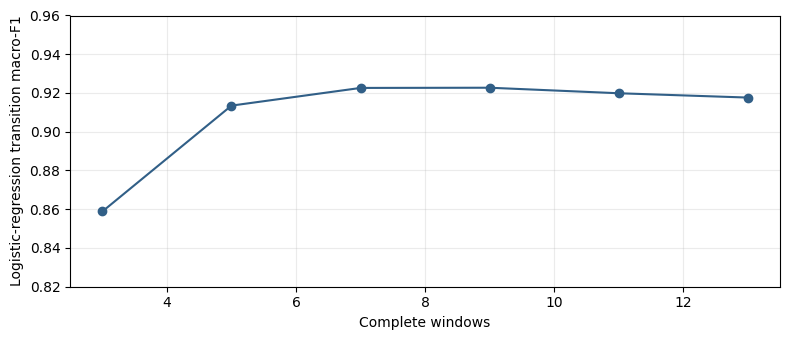

In [14]:
lr_length_validation = pd.DataFrame([{'window': 3, 'transition_f1_mean': 0.85886, 'transition_f1_sd': 0.036368, 'common_f1_mean': 0.932479}, {'window': 5, 'transition_f1_mean': 0.913482, 'transition_f1_sd': 0.042089, 'common_f1_mean': 0.937118}, {'window': 7, 'transition_f1_mean': 0.922613, 'transition_f1_sd': 0.034504, 'common_f1_mean': 0.943002}, {'window': 9, 'transition_f1_mean': 0.922719, 'transition_f1_sd': 0.038711, 'common_f1_mean': 0.950124}, {'window': 11, 'transition_f1_mean': 0.919866, 'transition_f1_sd': 0.043056, 'common_f1_mean': 0.955396}, {'window': 13, 'transition_f1_mean': 0.917642, 'transition_f1_sd': 0.04106, 'common_f1_mean': 0.958629}])
display(lr_length_validation.round(4))
ax = lr_length_validation.plot(x="window", y="transition_f1_mean", marker="o", legend=False,
                                figsize=(8, 3.5), color="#315f87")
ax.set_ylim(0.82, 0.96)
ax.set_ylabel("Logistic-regression transition macro-F1")
ax.set_xlabel("Complete windows")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [15]:
# Optional exact rerun of any measured context length on three grouped folds.
RUN_WINDOW_SWEEP = False
if RUN_WINDOW_SWEEP:
    rows = []
    for model_name, group in recorded_window_cv.groupby("model"):
        for window in group.window:
            weight = 0 if model_name == "lda" else 0.5
            folds = evaluate_cv(model_name, context=int(window), weight_exponent=weight,
                                lda_memory=False)
            rows.append({"model": model_name, "window": window,
                         "transition_f1": folds.transition_f1.mean(),
                         "common_f1": folds.common_f1.mean(),
                         "mean_seconds_per_fold": folds.elapsed_seconds.mean()})
    display(pd.DataFrame(rows).round(4))


In [17]:
RUN_LDA_MEMORY_CHECK = False
if RUN_LDA_MEMORY_CHECK:
    memory_rows = []
    for window in sorted(lda_window_folds):
        for use_memory in [False, True]:
            folds = evaluate_cv(
                "lda", context=window, weight_exponent=0, lda_memory=use_memory)
            memory_rows.append({
                "window": window, "memory": use_memory,
                "transition_f1": folds.transition_f1.mean(),
                "common_f1": folds.common_f1.mean()})
    display(pd.DataFrame(memory_rows).round(4))

## 5. Try PCA to reduce the cost of full-window context

Input size grows linearly: 3, 7, 9 and 11 complete windows contain **1,683**, **3,927**, **5,049** and **6,171** features. Context improves the measured validation scores, but this does not establish that high dimensionality is harmless: feature count changes together with the information supplied. We evaluate PCA primarily as a way to reduce computation while retaining predictive quality.

Scaling and PCA are fitted only on each training fold. Timing covers scaling, PCA fit/transform where used, model fit and prediction; it excludes data loading and shared context construction. We count a useful speedup only when both transition and common F1 decline by no more than 0.005 and total measured fold time falls. Timings depend on the machine and workload. Logistic regression's recorded PCA-400 comparison saves about 28–39% in paired timings while staying within the validation tolerance; PCA is not a reliable speedup for every model.

For LDA, keep seven windows, posture memory, automatic shrinkage, equal priors and no weighting or oversampling fixed. Compare raw features with PCA-200/400/500 on the same three participant folds, using a fresh timed raw baseline with memory on. A PCA option must meet both F1 tolerances and run faster than raw features in two timing comparisons. In the first comparison, run raw before PCA; in the second, run PCA before raw. If several pass, choose the fastest mean time across both runs; otherwise retain raw. If two PCA options have exactly the same average runtime, choose the one with fewer components. The Section 4 scores remain the pre-PCA window/memory comparison.

In [18]:
pca_benchmark = pd.DataFrame([('logreg', 7, 'raw', 0.908785, 0.941388, 8.4148),
 ('logreg', 7, 'pca200', 0.902167, 0.928814, 5.6587),
 ('logreg', 7, 'pca400', 0.904761, 0.937162, 5.1143),
 ('logreg', 7, 'pca500', 0.909002, 0.938429, 8.9205),
 ('random_forest', 9, 'raw', 0.920133, 0.915836, 50.3278),
 ('random_forest', 9, 'pca200', 0.775097, 0.885711, 16.5596),
 ('random_forest', 9, 'pca500', 0.677763, 0.881158, 32.4642),
 ('xgboost', 7, 'raw', 0.903337, 0.931203, 381.0929),
 ('xgboost', 7, 'pca200', 0.802911, 0.888043, 29.5112),
 ('xgboost', 7, 'pca500', 0.82239, 0.895625, 73.2859),
 ('mlp', 11, 'raw', 0.930245, 0.932897, 20.865),
 ('mlp', 11, 'pca200', 0.920188, 0.937842, 9.735),
 ('mlp', 11, 'pca500', 0.947498, 0.956694, 18.8957),
 ('linear_svm', 7, 'raw', 0.883384, 0.944815, None),
 ('linear_svm', 7, 'pca200', 0.901008, 0.921912, 2.3265),
 ('linear_svm', 7, 'pca500', 0.895535, 0.932049, 5.8431),
 ('lda', 7, 'raw', 0.9698615182009264, 0.9468952165339223, 35.31513006663105),
 ('lda', 7, 'pca200', 0.8711287271949765, 0.9130282268377942, 1.1939860666558768),
 ('lda', 7, 'pca400', 0.9295627532930455, 0.9247177969111396, 1.5732773000296827),
 ('lda', 7, 'pca500', 0.9516075870110784, 0.9294008305148526, 1.9327321333500247)], columns=['model', 'window', 'representation', 'transition_f1', 'common_f1', 'mean_seconds_per_fold'])
raw = pca_benchmark[pca_benchmark.representation == "raw"].set_index("model")
pca_comparison = pca_benchmark.copy()
pca_comparison["transition_change"] = pca_comparison.apply(lambda r: r.transition_f1 - raw.loc[r.model, "transition_f1"], axis=1)
pca_comparison["common_change"] = pca_comparison.apply(lambda r: r.common_f1 - raw.loc[r.model, "common_f1"], axis=1)
pca_comparison["time_saved_pct"] = pca_comparison.apply(lambda r: 100 * (1 - r.mean_seconds_per_fold / raw.loc[r.model, "mean_seconds_per_fold"]), axis=1)
pca_comparison["single_run_pass"] = ((pca_comparison.transition_change >= -0.005) &
                                     (pca_comparison.common_change >= -0.005) &
                                     (pca_comparison.time_saved_pct > 0))
display(pca_comparison.round(4))

# Two same-fold, same-machine timing repetitions for the near-lossless candidates.
paired_timing = pd.DataFrame([
    {"Model": "Logistic regression", "Representation": "PCA-400", "Run": 1, "Raw s/fold": 2.7334, "PCA s/fold": 1.9696},
    {"Model": "Logistic regression", "Representation": "PCA-400", "Run": 2, "Raw s/fold": 8.4148, "PCA s/fold": 5.1143},
    {"Model": "MLP", "Representation": "PCA-500", "Run": 1, "Raw s/fold": 20.8650, "PCA s/fold": 18.8957},
    {"Model": "MLP", "Representation": "PCA-500", "Run": 2, "Raw s/fold": 16.5424, "PCA s/fold": 19.0061},
])
paired_timing["Time saved %"] = 100 * (1 - paired_timing["PCA s/fold"] / paired_timing["Raw s/fold"])
display(paired_timing.round(2))

# Selected from the LDA validation quality and timing results.
selected_lda_representation = 'raw'


,model,window,representation,transition_f1,common_f1,mean_seconds_per_fold,transition_change,common_change,time_saved_pct,single_run_pass
0,logreg,7,raw,0.9088,0.9414,8.4148,0.0000,0.0000,0.0000,False
1,logreg,7,pca200,0.9022,0.9288,5.6587,-0.0066,-0.0126,32.7530,False
2,logreg,7,pca400,0.9048,0.9372,5.1143,-0.0040,-0.0042,39.2226,True
3,logreg,7,pca500,0.9090,0.9384,8.9205,0.0002,-0.0030,-6.0096,False
4,random_forest,9,raw,0.9201,0.9158,50.3278,0.0000,0.0000,0.0000,False
5,random_forest,9,pca200,0.7751,0.8857,16.5596,-0.1450,-0.0301,67.0965,False
6,random_forest,9,pca500,0.6778,0.8812,32.4642,-0.2424,-0.0347,35.4945,False
7,xgboost,7,raw,0.9033,0.9312,381.0929,0.0000,0.0000,0.0000,False
8,xgboost,7,pca200,0.8029,0.8880,29.5112,-0.1004,-0.0432,92.2562,False
9,xgboost,7,pca500,0.8224,0.8956,73.2859,-0.0809,-0.0356,80.7695,False


,Model,Representation,Run,Raw s/fold,PCA s/fold,Time saved %
0,Logistic regression,PCA-400,1,2.73,1.97,27.94
1,Logistic regression,PCA-400,2,8.41,5.11,39.22
2,MLP,PCA-500,1,20.86,18.90,9.44
3,MLP,PCA-500,2,16.54,19.01,-14.89


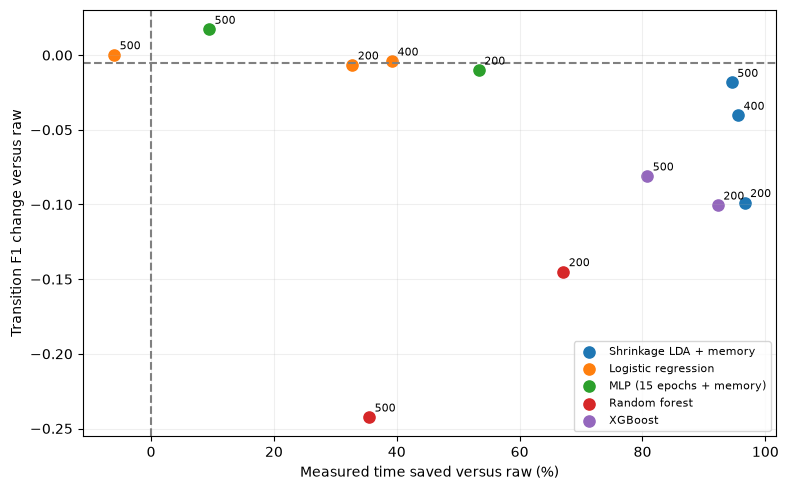

In [19]:
pca_model_names = {**model_names, "lda": "Shrinkage LDA + memory"}
fig, ax = plt.subplots(figsize=(8, 5))
for model_name, group in pca_comparison[(pca_comparison.representation != "raw") & np.isfinite(pca_comparison.time_saved_pct)].groupby("model"):
    ax.scatter(group.time_saved_pct, group.transition_change, label=pca_model_names[model_name], s=65)
    for r in group.itertuples():
        ax.annotate(r.representation.replace("pca", ""), (r.time_saved_pct, r.transition_change), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axhline(-0.005, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle="--")
ax.set(xlabel="Measured time saved versus raw (%)", ylabel="Transition F1 change versus raw")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
# Reproduce the matched PCA comparisons. This can take substantial time.
RUN_PCA_BENCHMARK = False
if RUN_PCA_BENCHMARK:
    rows = []
    for model_name, window in selected_windows.items():
        representations = ("raw", "pca200", "pca400", "pca500") if model_name in ("logreg", "lda") else ("raw", "pca200", "pca500")
        weight = 0 if model_name == "lda" else 0.5
        for representation in representations:
            folds = evaluate_cv(
                model_name, context=window, weight_exponent=weight, representation=representation,
                lda_memory=selected_lda_memory if model_name == "lda" else False)
            rows.append({"model": model_name, "window": window, "representation": representation,
                         "transition_f1": folds.transition_f1.mean(), "common_f1": folds.common_f1.mean(),
                         "mean_seconds_per_fold": folds.elapsed_seconds.mean()})
    display(pd.DataFrame(rows).round(4))


**PCA helps selectively.** For seven-window logistic regression, PCA-400 changes validation transition F1 from 0.9088 to 0.9048 and common F1 from 0.9414 to 0.9372: both losses stay within the 0.005 tolerance. Two paired runs take about **28%** and **39%** less time. PCA-200/500 makes random forest and XGBoost faster but substantially damages transition F1. PCA-200 lowers MLP transition F1 by about 0.010; PCA-500 improves its F1, yet repeated timings disagree on whether it is faster. SVM's tested PCA settings reduce common-class F1 beyond the tolerance, and its raw runtime lacks a stable comparison. Hence PCA-400 is the supported speed choice for logistic regression; linear SVM, random forest, XGBoost and MLP retain raw features.

For **LDA with posture memory**, PCA substantially reduces runtime, but all three settings lower both transition and common-class F1 by more than the 0.005 tolerance. We therefore **retain raw features**.

## 6. Final configurations and descriptive test comparison

The window lengths come from grouped validation in step 4. We apply PCA-400 only to logistic regression because it has the repeatable speed benefit in step 5; the other models use raw features. Logistic regression, linear SVM, XGBoost, random forest and MLP use mild weighting; LDA uses equal priors. None uses oversampling. The table reports one refit on all training participants evaluated on the same 3,162 test windows. **Test results describe these preselected configurations; they did not choose the window lengths.**

| Model | Final input | Validation transition F1 | Test transition F1 | Test transition recall | Test common F1 | Test macro F1 | Test accuracy |
|---|---|---:|---:|---:|---:|---:|---:|
| Logistic regression | 7 × 561, PCA-400 | 0.9048 | 0.9373 | 0.9311 | 0.9615 | 0.9494 | 0.9592 |
| Linear SVM | 7 × 561, Raw | 0.8834 | 0.9322 | 0.9205 | 0.9784 | 0.9553 | 0.9741 |
| XGBoost | 7 × 561, Raw | 0.9033 | 0.9285 | 0.9387 | 0.9696 | 0.9491 | 0.9681 |
| Random forest | 9 × 561, Raw | 0.9201 | 0.9296 | 0.9046 | 0.9344 | 0.9320 | 0.9345 |
| MLP + posture memory | 11 × 561, Raw | 0.9302 | 0.9716 | 0.9552 | 0.9766 | 0.9741 | 0.9756 |
| Shrinkage LDA + posture memory | 7 × 561, Raw | 0.9699 | 0.9779 | 0.9736 | 0.9787 | 0.9783 | 0.9782 |

**Best by the primary validation measure among the six retained configurations:** shrinkage LDA with posture memory at seven windows using raw features, with transition F1 **0.9699** on the three-fold validation. Its test macro precision/recall/F1 are **0.9811 / 0.9760 / 0.9783**, with accuracy **0.9782**. For transitions alone, precision/recall/F1 are **0.9829 / 0.9736 / 0.9779**. MLP with posture memory also performs strongly, reaching test transition F1 **0.9716** and macro-F1 **0.9741**, slightly below LDA’s recorded scores. This is a practical selection within the tested settings, not a claim that the test set proves a general winner.

### Per-class test recall: MLP and LDA

Recall is the number of correctly classified test windows divided by that class's test support. MLP uses eleven windows with mild weighting; LDA uses seven windows with equal priors. Both use raw features and posture memory.

| Class ID | Activity | Test support | MLP correct | MLP recall | LDA correct | LDA recall |
|---:|---|---:|---:|---:|---:|---:|
| 1 | WALKING | 496 | 491 | 98.99% | 495 | 99.80% |
| 2 | WALKING_UPSTAIRS | 471 | 467 | 99.15% | 470 | 99.79% |
| 3 | WALKING_DOWNSTAIRS | 420 | 415 | 98.81% | 407 | 96.90% |
| 4 | SITTING | 508 | 475 | 93.50% | 472 | 92.91% |
| 5 | STANDING | 556 | 535 | 96.22% | 544 | 97.84% |
| 6 | LAYING | 545 | 544 | 99.82% | 544 | 99.82% |
| 7 | STAND_TO_SIT | 23 | 20 | 86.96% | 22 | 95.65% |
| 8 | SIT_TO_STAND | 10 | 10 | 100.00% | 10 | 100.00% |
| 9 | SIT_TO_LIE | 32 | 32 | 100.00% | 32 | 100.00% |
| 10 | LIE_TO_SIT | 25 | 24 | 96.00% | 25 | 100.00% |
| 11 | STAND_TO_LIE | 49 | 46 | 93.88% | 47 | 95.92% |
| 12 | LIE_TO_STAND | 27 | 26 | 96.30% | 25 | 92.59% |



### Error analysis of seven-window LDA with posture memory

The following analysis uses the selected raw-feature LDA pipeline and its saved predictions on all 3,162 test windows.

#### Per-transition precision, recall and F1

Precision counts false positives from every test class, including common activities predicted as transitions. Support is the number of true test windows for each activity.

| Class ID | Transition | Test support | Precision | Recall | F1 |
|---:|---|---:|---:|---:|---:|
| 7 | STAND_TO_SIT | 23 | 0.9565 | 0.9565 | 0.9565 |
| 8 | SIT_TO_STAND | 10 | 1.0000 | 1.0000 | 1.0000 |
| 9 | SIT_TO_LIE | 32 | 1.0000 | 1.0000 | 1.0000 |
| 10 | LIE_TO_SIT | 25 | 0.9615 | 1.0000 | 0.9804 |
| 11 | STAND_TO_LIE | 49 | 0.9792 | 0.9592 | 0.9691 |
| 12 | LIE_TO_STAND | 27 | 1.0000 | 0.9259 | 0.9615 |

#### Confusion matrix

Rows are actual activity IDs and columns are predicted IDs, using the activity mapping in the per-class recall table. Counts include all twelve classes, so both missed transitions and common-to-transition false positives remain visible.

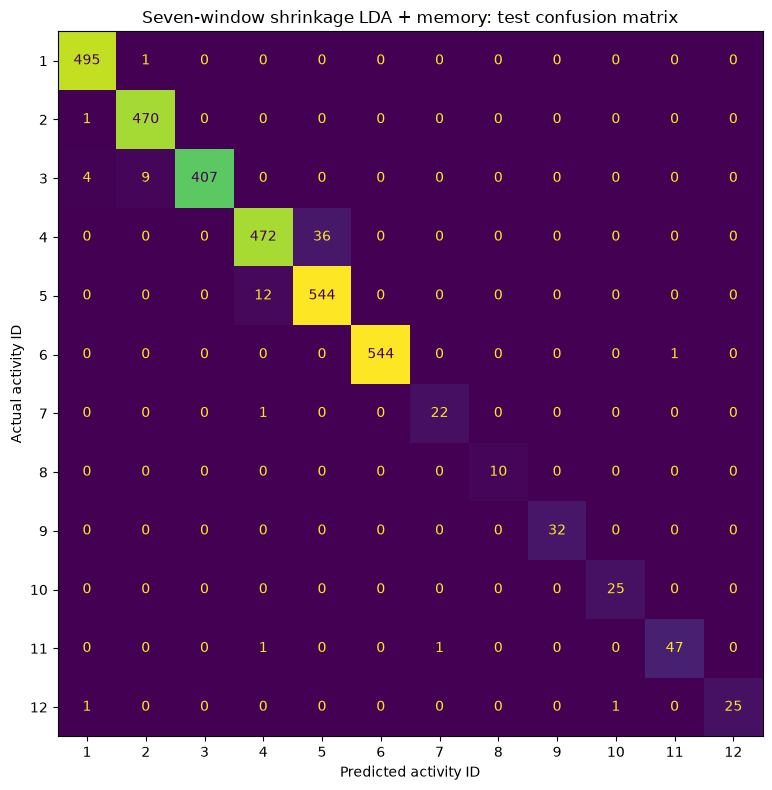

In [1]:
# Recorded confusion counts for the selected LDA pipeline.
lda_test_confusion = np.array([
    [495, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 470, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [4, 9, 407, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 472, 36, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 12, 544, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 544, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0, 22, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 10, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 32, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 25, 0, 0],
    [0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 47, 0],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 25],
], dtype=int)

from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(lda_test_confusion, display_labels=LABELS).plot(
    ax=ax, colorbar=False, values_format="d")
ax.set(title="Seven-window shrinkage LDA + memory: test confusion matrix",
       xlabel="Predicted activity ID", ylabel="Actual activity ID")
plt.tight_layout()
plt.show()

#### Individual test errors involving transitions

All six misclassified windows with a transition as the actual or predicted activity are shown below. Five are true transition windows; the LAYING row is a common-activity false positive. `test_row` is a zero-based row position in `hapt_test.csv`, excluding the header; it is not a timestamp. Activity IDs elsewhere remain 1-based.

| Test row | Participant | Actual activity | Predicted activity |
|---:|---:|---|---|
| 1163 | 10 | LAYING | STAND_TO_LIE |
| 1989 | 18 | STAND_TO_SIT | SITTING |
| 2808 | 24 | STAND_TO_LIE | STAND_TO_SIT |
| 2810 | 24 | STAND_TO_LIE | SITTING |
| 2871 | 24 | LIE_TO_STAND | LIE_TO_SIT |
| 2874 | 24 | LIE_TO_STAND | WALKING |

#### Interpretation and future improvements

**Remaining transition weaknesses.** LDA correctly classifies 161 of the 166 true transition windows. STAND_TO_SIT has the lowest transition F1 (0.9565), while LIE_TO_STAND has the lowest recall (25/27, or 92.59%). SIT_TO_STAND and SIT_TO_LIE have perfect precision and recall in this test sample, based on only 10 and 32 windows respectively. LIE_TO_SIT illustrates why recall alone is insufficient: all 25 true windows are recognised, but the LIE_TO_STAND false positive lowers its precision to 0.9615 and F1 to 0.9804. The LAYING-to-STAND_TO_LIE error also lowers transition precision despite originating from a common activity.

**Where the errors occur.** Four of the five true transition errors belong to participant 24. Rows 2808 and 2871 confuse transitions sharing the same starting posture but different destinations. Row 1989 is the last STAND_TO_SIT-labelled row before SITTING at row 1990; row 2874 is the last LIE_TO_STAND-labelled row before WALKING at row 2875. Conversely, row 1163 is the first LAYING-labelled row after STAND_TO_LIE at row 1162. These adjacent-label patterns suggest possible ambiguity around activity changes, but they do not establish a physical cause. The prepared CSV has no exact timestamps or within-participant recording IDs, so confirming motion or boundary explanations requires further inspection of the raw recordings.

**Common-activity trade-offs.** Of all 69 classification errors, 48 are SITTING/STANDING swaps and 13 are WALKING_DOWNSTAIRS windows predicted as another walking activity. These confusions account for most remaining errors even though the project prioritises rare transitions. Compared with MLP's recorded class counts, LDA misses fewer true transition windows overall (5 versus 8), but MLP recognises more LIE_TO_STAND windows (26/27 versus 25/27). Their different window lengths and imbalance treatments mean this comparison does not isolate the effect of classifier family alone.

**Future work.** The fixed memory rule only switches SIT_TO_LIE and STAND_TO_LIE predictions; it cannot correct predictions such as LIE_TO_SIT, SITTING or WALKING. Future studies could inspect the listed recordings, validate recording-aware context and additional posture cues using training participants, and collect more rare-transition examples across participants. The error cases motivate these checks; they do not justify changing the selected pipeline based on its test errors.

### Error analysis of the raw seven-window logistic-regression reference

The cell below refits the raw seven-window logistic-regression model to inspect individual errors. It differs from the PCA-400 logistic-regression row in the final comparison, so its printed score and confusion matrix should be read as a diagnostic reference.

{'transition_f1': 0.9314048696401637, 'transition_recall': 0.925484474788305, 'common_f1': 0.9695967435098097, 'accuracy': 0.9664769133459835}


,activity_id,support,precision,recall,f1
0,1,496,0.9821,0.9960,0.9890
1,2,471,0.9729,0.9915,0.9821
2,3,420,0.9926,0.9643,0.9783
3,4,508,0.9566,0.9114,0.9335
4,5,556,0.9195,0.9658,0.9421
5,6,545,0.9963,0.9890,0.9926
6,7,23,1.0000,0.9565,0.9778
7,8,10,0.9091,1.0000,0.9524
8,9,32,0.9286,0.8125,0.8667
9,10,25,0.9231,0.9600,0.9412


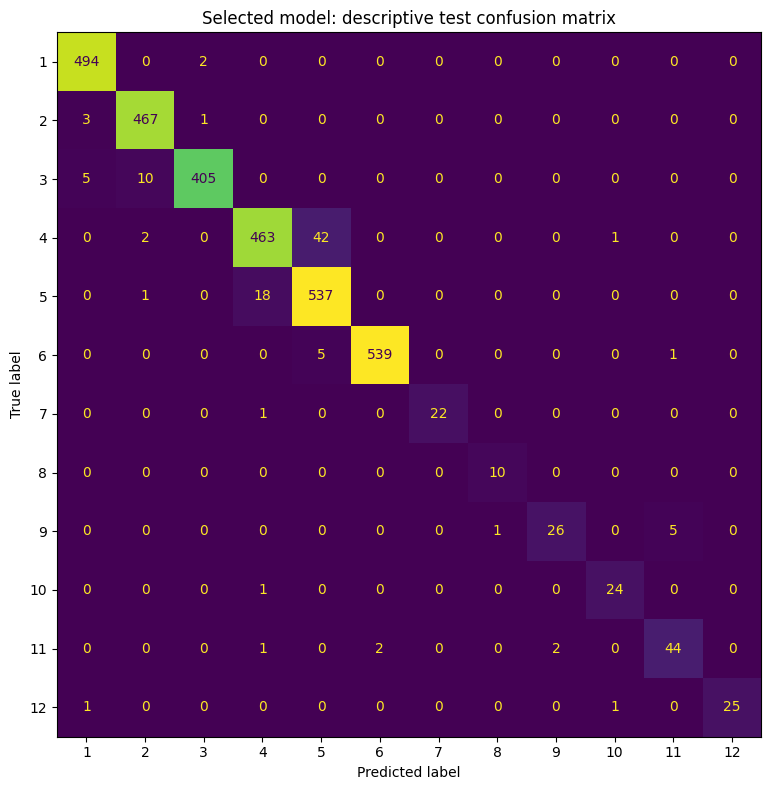

,test_row,participant,actual,predicted
0,50,2,11,9
1,51,2,11,6
2,65,2,10,4
3,1038,10,9,11
4,1188,10,9,8
5,1989,18,7,4
6,2434,20,11,6
7,2470,20,9,11
8,2471,20,9,11
9,2660,20,9,11


In [19]:
# Refit the raw seven-window logistic-regression reference for error analysis.
RUN_SELECTED_TEST = True
SELECTED_MODEL = "logreg"
SELECTED_WINDOW = selected_windows["logreg"]
if RUN_SELECTED_TEST:
    selected_score = evaluate_test(SELECTED_MODEL, context=SELECTED_WINDOW,
                                   weight_exponent=0.5)
    print({name: selected_score[name] for name in
           ("transition_f1", "transition_recall", "common_f1", "accuracy")})
    details = pd.DataFrame({"activity_id": LABELS,
                            "support": selected_score["support"],
                            "precision": selected_score["per_class_precision"],
                            "recall": selected_score["per_class_recall"],
                            "f1": selected_score["per_class_f1"]})
    display(details.round(4))
    from sklearn.metrics import ConfusionMatrixDisplay
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_test, selected_score["predictions"], labels=LABELS)
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, colorbar=False)
    ax.set_title("Selected model: descriptive test confusion matrix")
    plt.tight_layout()
    plt.show()
    wrong = np.flatnonzero((y_test != selected_score["predictions"]) &
                           np.isin(y_test, TRANSITION_LABELS))
    cases = pd.DataFrame({"test_row": wrong[:20],
                          "participant": groups_test[wrong[:20]],
                          "actual": y_test[wrong[:20]],
                          "predicted": selected_score["predictions"][wrong[:20]]})
    display(cases)

**Instance-level diagnosis of the raw logistic-regression reference.** In the seven-window test output above, 15 transition windows are misclassified. Four sit-to-lie windows from participant 20 (rows 2470, 2471, 2660 and 2661) are predicted as stand-to-lie. This cluster suggests possible ambiguity about starting posture; the table identifies cases for sensor-trace inspection, not proof of a cause. Sit-to-lie has the lowest transition recall in this reference (0.8125).

## Reproduce the controlled comparisons

The optional cell below recomputes the baseline, previous-only context, weighting, three-window context and oversampling attempts with the shared implementation. It is off by default because the complete six-model sweep is expensive.

LDA uses equal priors with posture memory off; sample-weighting conditions are not applicable.

The [LDA companion notebook](companion/LDA%20external.ipynb) contains executable code and recorded results for the LDA validation experiments, PCA comparisons, test evaluations and error analysis, including the saved test predictions.

In [20]:
RUN_FULL_ABLATION = False
if RUN_FULL_ABLATION:
    rows = []
    metric_columns = ["transition_f1", "transition_recall", "common_f1", "seconds"]
    conditions = [("baseline", "single", 0.0, 0),
                  ("previous only", "previous", 0.0, 0),
                  ("weights only", "single", 0.5, 0),
                  ("three windows only", "bidirectional", 0.0, 0),
                  ("three windows + weights", "bidirectional", 0.5, 0),
                  ("plus ROS 60", "bidirectional", 0.5, 60),
                  ("plus ROS 100", "bidirectional", 0.5, 100)]
    for model_name in ("logreg", "linear_svm", "random_forest", "xgboost", "mlp", "lda"):
        for title, context, weight, ros in conditions:
            if model_name == "lda" and title in ("weights only", "three windows + weights"):
                rows.append({"model": model_name, "condition": title,
                             **dict.fromkeys(metric_columns, np.nan)})
                continue
            weight = 0 if model_name == "lda" else weight
            folds = evaluate_cv(model_name, context=context, weight_exponent=weight,
                                oversample_target=ros, lda_memory=False)
            rows.append({"model": model_name, "condition": title,
                         "transition_f1": folds.transition_f1.mean(),
                         "transition_recall": folds.transition_recall.mean(),
                         "common_f1": folds.common_f1.mean(),
                         "seconds": folds.elapsed_seconds.sum()})
    rerun_ablation = pd.DataFrame(rows)
    rerun_display = rerun_ablation.round(4).astype(object)
    lda_weighting = ((rerun_ablation.model == "lda") &
                     rerun_ablation.condition.isin(["weights only", "three windows + weights"]))
    rerun_display.loc[lda_weighting, metric_columns] = "Not applicable"
    display(rerun_display)

## Appendix: optional MLP selection search

This exploratory search varies context, PCA, weighting, class caps, oversampling and stopping criteria, then checks a shortlist on additional participant splits. The selected 15-epoch network and posture-memory rule are already integrated in the main six-model comparisons.

In [21]:
RUN_MLP_TUNING = False

def run_mlp_tuning():
    from copy import deepcopy
    import torch
    import torch.nn.functional as F
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    X, y, subject = x_train, y_train - 1, groups_train
    names = train_df[["activity_id", "activity_label"]].drop_duplicates().sort_values("activity_id").activity_label.tolist()
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 0.0001
    BATCH_SIZE = 128
    MAX_EPOCHS = 100
    PATIENCE = 12
    ALLOW_NEXT_WINDOW = True
    views = {}
    rows = np.arange(len(X))
    for name, offsets in [('single', [0]), ('past2', [-1, 0]),
                          ('past3', [-2, -1, 0]), ('offline3', [-1, 0, 1])]:
        blocks = []
        for offset in offsets:
            neighbor = np.clip(rows + offset, 0, len(X) - 1)
            boundary = subject[neighbor] != subject
            neighbor[boundary] = rows[boundary]
            blocks.append(X[neighbor])
        views[name] = np.hstack(blocks)
    print('Input dimensions:', {name: values.shape[1] for name, values in views.items()})


    def make_model(inputs):
        model = nn.Sequential(
            nn.Linear(inputs, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 12),
        )
        for layer in model:
            if isinstance(layer, nn.Linear):
                if layer.out_features == 12:
                    nn.init.xavier_uniform_(layer.weight)
                else:
                    nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                nn.init.zeros_(layer.bias)
        return model


    def memory_predictions(probabilities, people):
        prediction = probabilities.argmax(axis=1)
        gate = np.isin(prediction, [8, 10])
        mass = probabilities[:, [8, 10]].sum(axis=1)
        score = np.divide(probabilities[:, 10], mass, out=np.full(len(people), 0.5), where=mass > 0)
        start = 0
        for row in range(len(people)):
            if row == 0 or people[row] != people[row - 1]:
                start = row
            past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
            if past.sum() >= 0.75:
                score[row] = past[1] / past.sum()
        prediction[gate] = np.where(score[gate] > 0.5, 10, 8)
        return prediction


    def fit_fold(config, tr, va, fold, split_seed):
        name, context, components, limit, exponent, ros, stopping = config
        seed = split_seed + fold
        features = views[context]
        rng = np.random.default_rng(seed)
        selected = []
        for activity in range(12):
            rows = np.flatnonzero(y[tr] == activity)
            if activity < 6 and limit and len(rows) > limit:
                rows = rng.choice(rows, limit, replace=False)
            selected.extend(rows)
        sampled = tr[np.sort(selected)]
        counts = np.bincount(y[sampled], minlength=12)
        weights = torch.tensor((len(sampled) / (12 * counts)) ** exponent, dtype=torch.float32)
        if ros:
            extra = []
            for activity in range(6, 12):
                found = sampled[y[sampled] == activity]
                if len(found) < ros:
                    extra.extend(rng.choice(found, ros - len(found), replace=True))
            sampled = np.concatenate((sampled, np.asarray(extra, dtype=int)))
        scaler = StandardScaler()
        train_x = scaler.fit_transform(features[sampled]).astype(np.float32)
        val_x = scaler.transform(features[va]).astype(np.float32)
        if components:
            pca = PCA(n_components=components, svd_solver='randomized', random_state=seed)
            train_x = pca.fit_transform(train_x).astype(np.float32)
            val_x = pca.transform(val_x).astype(np.float32)
        train_y = y[sampled]
        tx, ty, vx = torch.from_numpy(train_x), torch.from_numpy(train_y), torch.from_numpy(val_x)
        vy = torch.from_numpy(y[va])
        torch.manual_seed(seed)
        model = make_model(train_x.shape[1])
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        loader = DataLoader(TensorDataset(tx, ty), batch_size=BATCH_SIZE, shuffle=True,
                            generator=torch.Generator().manual_seed(seed))
        best_score = -1.0
        best_epoch = 0
        history = []
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            for bx, by in loader:
                optimizer.zero_grad()
                logits = model(bx)
                losses = F.cross_entropy(logits, by, reduction='none')
                loss = (losses * weights[by]).sum() / weights[by].sum()
                loss.backward()
                optimizer.step()
            model.eval()
            with torch.no_grad():
                train_logits = model(tx)
                losses = F.cross_entropy(train_logits, ty, reduction='none')
                train_loss = (losses * weights[ty]).sum() / weights[ty].sum()
                val_logits = model(vx)
                losses = F.cross_entropy(val_logits, vy, reduction='none')
                val_loss = (losses * weights[vy]).sum() / weights[vy].sum()
                f = precision_recall_fscore_support(y[va], val_logits.argmax(1).numpy(), labels=range(12), zero_division=0)[2]
            score = float(f.mean() if stopping == 'all' else f[6:].mean())
            history.append({'epoch': epoch, 'train_loss': train_loss.item(), 'validation_loss': val_loss.item(),
                            'transition_f1': float(f[6:].mean()), 'macro_f1': float(f.mean())})
            if score > best_score + 1e-6:
                best_score, best_epoch = score, epoch
                best_weights = deepcopy(model.state_dict())
            if epoch - best_epoch >= PATIENCE:
                break
        model.load_state_dict(best_weights)
        model.eval()
        with torch.no_grad():
            probabilities = model(vx).softmax(1).numpy()
        result = {'config': config, 'split_seed': split_seed, 'fold': fold,
                  'best_epoch': best_epoch, 'stop_epoch': epoch, 'history': history}
        for method, prediction in [('plain', probabilities.argmax(1)),
                                   ('memory', memory_predictions(probabilities, subject[va]))]:
            p, r, f, n = precision_recall_fscore_support(
                y[va], prediction, labels=range(12), zero_division=0)
            result[method] = {'transition_f1': float(f[6:].mean()),
                              'common_f1': float(f[:6].mean()), 'macro_f1': float(f.mean()),
                              'accuracy': float(np.mean(y[va] == prediction)),
                              'transition_recall': float(r[6:].mean()),
                              'class_f1': f.tolist(), 'class_recall': r.tolist()}
        return result


    trials = [
        ('current', 'single', 200, 300, 1.0, 0, 'all'),
        ('transition_stop', 'single', 200, 300, 1.0, 0, 'transition'),
        ('mild_weights_only', 'single', 200, 300, 0.5, 0, 'transition'),
        ('all_rows_only', 'single', 200, 0, 1.0, 0, 'transition'),
        ('no_pca_only', 'single', 0, 300, 1.0, 0, 'transition'),
        ('past2_only', 'past2', 200, 300, 1.0, 0, 'transition'),
        ('past3_only', 'past3', 200, 300, 1.0, 0, 'transition'),
        ('offline3_only', 'offline3', 200, 300, 1.0, 0, 'transition'),
        ('past2_full_raw_mild', 'past2', 0, 0, 0.5, 0, 'transition'),
        ('past3_full_raw_mild', 'past3', 0, 0, 0.5, 0, 'transition'),
        ('offline3_full_raw_mild', 'offline3', 0, 0, 0.5, 0, 'transition'),
        ('offline_raw_unweighted', 'offline3', 0, 0, 0.0, 0, 'transition'),
        ('offline_raw_inverse', 'offline3', 0, 0, 1.0, 0, 'transition'),
        ('offline_all_pca_mild', 'offline3', 200, 0, 0.5, 0, 'transition'),
        ('offline_cap_raw_mild', 'offline3', 0, 300, 0.5, 0, 'transition'),
        ('offline_ros60', 'offline3', 0, 0, 0.5, 60, 'transition'),
        ('offline_ros100', 'offline3', 0, 0, 0.5, 100, 'transition'),
        ('past2_raw_unweighted', 'past2', 0, 0, 0.0, 0, 'transition'),
        ('past2_raw_inverse', 'past2', 0, 0, 1.0, 0, 'transition'),
    ]


    results = []
    folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=42).split(X, y, subject))
    for trial in trials:
        for fold, (tr, va) in enumerate(folds, 1):
            result = fit_fold(trial, tr, va, fold, split_seed=42)
            results.append(result)
            print(f'{trial[0]}, fold {fold}: NN={result["plain"]["transition_f1"]:.4f}, '
                  f'+memory={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


    print(f'{"Trial":27} {"NN transition F1":>17} {"+memory F1":>12} {"Common F1":>11}')
    for trial in trials:
        group = [r for r in results if r['config'][0] == trial[0]]
        plain = np.mean([r['plain']['transition_f1'] for r in group])
        memory_score = np.mean([r['memory']['transition_f1'] for r in group])
        common = np.mean([r['memory']['common_f1'] for r in group])
        print(f'{trial[0]:27} {plain:17.4f} {memory_score:12.4f} {common:11.4f}')


    ranked = []
    for trial in trials:
        group = [r for r in results if r['config'][0] == trial[0]]
        score = max(np.mean([r[method]['transition_f1'] for r in group])
                    for method in ['plain', 'memory'])
        ranked.append((score, trial))
    ranked.sort(key=lambda item: item[0], reverse=True)
    offline = [trial for score, trial in ranked if trial[1] == 'offline3'][:4]
    past_only = [trial for score, trial in ranked if trial[1] != 'offline3' and trial[0] != 'current'][:1]
    shortlist = [trials[0]] + offline + past_only

    for trial in shortlist:
        for split_seed in [123, 2026]:
            folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=split_seed).split(X, y, subject))
            for fold, (tr, va) in enumerate(folds, 1):
                result = fit_fold(trial, tr, va, fold, split_seed)
                results.append(result)
                print(f'{trial[0]}, seed {split_seed}, fold {fold}: '
                      f'+memory F1={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


    reference = [r for r in results if r['config'][0] == 'current']
    minimum_common = np.mean([r['memory']['common_f1'] for r in reference]) - 0.01
    choices = []
    print(f'{"Shortlist":27} {"Method":>8} {"Transition F1":>14} {"Fold SD":>9} {"Common F1":>11}')
    for trial in shortlist:
        group = [r for r in results if r['config'][0] == trial[0]]
        for method in ['plain', 'memory']:
            values = [r[method]['transition_f1'] for r in group]
            mean = float(np.mean(values))
            common = float(np.mean([r[method]['common_f1'] for r in group]))
            print(f'{trial[0]:27} {method:>8} {mean:14.4f} {np.std(values, ddof=1):9.4f} {common:11.4f}')
            if common >= minimum_common and (ALLOW_NEXT_WINDOW or trial[1] != 'offline3'):
                choices.append((mean, trial, method))
    best_score, best_trial, best_method = max(choices, key=lambda item: item[0])
    chosen = [r for r in results if r['config'][0] == best_trial[0]]
    final_epochs = int(np.median([r['best_epoch'] for r in chosen]))
    print('\nSelected:', best_trial[0], '| Method:', best_method)
    print('Best epochs:', [r['best_epoch'] for r in chosen], '| Final duration:', final_epochs)


    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for column, result in enumerate([r for r in chosen if r['split_seed'] == 42]):
        history = result['history']
        epochs = [row['epoch'] for row in history]
        axes[0, column].plot(epochs, [row['train_loss'] for row in history], label='Training')
        axes[0, column].plot(epochs, [row['validation_loss'] for row in history], label='Validation')
        axes[0, column].axvline(result['best_epoch'], color='green', linestyle='--')
        axes[0, column].set(title=f'Fold {column + 1}', xlabel='Epoch', ylabel='Weighted loss')
        axes[0, column].legend()
        axes[1, column].plot(epochs, [row['transition_f1'] for row in history])
        axes[1, column].axvline(result['best_epoch'], color='green', linestyle='--')
        axes[1, column].set(xlabel='Epoch', ylabel='Validation transition F1')
    fig.tight_layout()
    plt.show()


    old_f1 = np.mean([r['memory']['class_f1'] for r in reference], axis=0)
    new_f1 = np.mean([r[best_method]['class_f1'] for r in chosen], axis=0)
    print(f'{"Transition":22} {"Previous F1":>12} {"Selected F1":>12} {"Change":>9}')
    for activity in range(6, 12):
        print(f'{names[activity]:22} {old_f1[activity]:12.4f} {new_f1[activity]:12.4f}'
              f' {new_f1[activity] - old_f1[activity]:+9.4f}')

    return best_trial, best_method, final_epochs, results

if RUN_MLP_TUNING:
    mlp_selection = run_mlp_tuning()

## Appendix: archived exploratory model code

These collapsed listings preserve earlier logistic-regression, random-forest, XGBoost and SVM experiment code inside this single notebook. The executable shared comparisons above are the basis for the reported results.

<details><summary>Original multinomial logistic regression — expand original code</summary>

```python
# Original cell 0
import numpy as np
import xgboost as xgb
import optuna
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Original cell 1
# input dataset
data_test = pd.read_csv('/content/drive/MyDrive/DSA/CS3244/data/hapt_test.csv')
data_train = pd.read_csv('/content/drive/MyDrive/DSA/CS3244/data/hapt_train.csv')

# Original cell 2
# seperate into x and y and modify to zero indexing for pca
data_test['activity_id'] = data_test['activity_id']-1
test_x = data_test.drop(columns=['subject_id', 'activity_label', 'activity_id'])
test_y = data_test['activity_id'].astype('category')

data_train['activity_id'] = data_train['activity_id']-1
train_x = data_train.drop(columns=['subject_id', 'activity_label', 'activity_id'])
train_y = data_train['activity_id'].astype('category')

# Original cell 4
X = train_x
y = train_y

# Create pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=500))
])

# Define grid of parameters to evaluate
param_grid = {
    'clf__C': [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Perform 5-fold cross-validation grid search
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X, y)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best 5-Fold Cross-Validation Score: {grid.best_score_:.4f}")

# Original cell 5
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(test_x)
model_logreg = LogisticRegression(
    multi_class='multinomial', solver='lbfgs', max_iter=500, C=1
)
model_logreg.fit(X_scaled, y)

y_pred = model_logreg.predict(X_test_scaled)
y_prob = model_logreg.predict_proba(X_scaled)

print(f'Accuracy: {accuracy_score(test_y, y_pred):.4f}\n')
# Convert unique targets to sorted strings to prevent TypeError
target_names = [str(label) for label in sorted(test_y.unique())]
print(classification_report(test_y, y_pred, target_names=target_names))
```

</details>

<details><summary>Original random forest with undersampling, PCA and weights — expand original code</summary>

```python
# Original cell 7
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight

# ==============================================================================
# Step 1: Load Data
# ==============================================================================
X_train = train_x
y_train = train_y
subject_train = data_train['subject_id']

X_test = test_x
y_test = test_y
subject_test = data_test['subject_id']

# Helper function for Step 3: Undersample basic activities (0-5)
def undersample_fold(X, y, groups, seed):
    rng = np.random.default_rng(seed)
    selected_indices = []

    for label in np.unique(y):
        label_indices = np.where(y == label)[0]
        if label <= 5:  # Basic activities: retain at most 300 windows
            if len(label_indices) > 300:
                chosen = rng.choice(label_indices, size=300, replace=False)
            else:
                chosen = label_indices
        else:  # Transition windows: keep all
            chosen = label_indices
        selected_indices.extend(chosen)

    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)  # Shuffle order of combined indices
    return X.iloc[selected_indices] if hasattr(X, 'iloc') else X[selected_indices], y.iloc[selected_indices] if hasattr(y, 'iloc') else y[selected_indices], groups.iloc[selected_indices] if hasattr(groups, 'iloc') else groups[selected_indices]


# ==============================================================================
# Steps 2–6: Stratified Group K-Fold Cross-Validation & Tuning
# ==============================================================================
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

val_scores = []

for fold, (train_idx, val_idx) in enumerate(sgkf.split(X_train, y_train, groups=subject_train)):
    # 2. Split into train/validation folds using .iloc for safe pandas indexing
    X_tr, y_tr, sub_tr = X_train.iloc[train_idx], y_train.iloc[train_idx], subject_train.iloc[train_idx]
    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

    # 3. Randomly retain at most 300 windows per basic activity (0-5) inside training fold
    seed = 42 + fold
    X_tr_sub, y_tr_sub, _ = undersample_fold(X_tr, y_tr, sub_tr, seed=seed)

    # 4. Fit StandardScaler on undersampled training fold only
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_sub)
    X_val_scaled = scaler.transform(X_val)

    # 5. Fit Randomized PCA (200 components) on undersampled training fold only
    pca = PCA(n_components=200, svd_solver="randomized", random_state=seed)
    X_tr_pca = pca.fit_transform(X_tr_scaled)
    X_val_pca = pca.transform(X_val_scaled)

    # 6. Compute class weights on undersampled training labels & train model
    classes = np.unique(y_tr_sub)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_tr_sub)
    class_weight_dict = dict(zip(classes, weights))

    clf = RandomForestClassifier(random_state=42, class_weight=class_weight_dict)
    clf.fit(X_tr_pca, y_tr_sub)

    # Evaluate on untouched validation set
    val_score = clf.score(X_val_pca, y_val)
    val_scores.append(val_score)
    print(f"Fold {fold + 1} Validation Accuracy: {val_score:.4f}")

print(f"Mean Validation Accuracy: {np.mean(val_scores):.4f}")


# ==============================================================================
# Step 7: Final Training on All 21 Training Participants & Testing
# ==============================================================================
# Repeat undersampling on full training dataset using seed 42
X_train_sub, y_train_sub, _ = undersample_fold(X_train, y_train, subject_train, seed=42)

# Fit scaler on undersampled full training set
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train_sub)
X_test_scaled = final_scaler.transform(X_test)

# Fit randomized PCA on undersampled full training set
final_pca = PCA(n_components=200, svd_solver="randomized", random_state=42)
X_train_pca = final_pca.fit_transform(X_train_scaled)
X_test_pca = final_pca.transform(X_test_scaled)

# Compute class weights on full undersampled training labels & fit final model
final_classes = np.unique(y_train_sub)
final_weights = compute_class_weight(class_weight="balanced", classes=final_classes, y=y_train_sub)
final_class_weight_dict = dict(zip(final_classes, final_weights))




# Original cell 9
RandomForest_model = RandomForestClassifier(random_state=42, class_weight=final_class_weight_dict)
RandomForest_model.fit(X_train_pca, y_train_sub)

# Evaluate final test accuracy on untouched test windows
test_accuracy = RandomForest_model.score(X_test_pca, y_test)
print(f"Final Test Accuracy: {test_accuracy:.4f}")

y_pred = RandomForest_model.predict(X_test_pca)
y_prob = RandomForest_model.predict_proba(X_train_pca)

print(f'Accuracy: {accuracy_score(test_y, y_pred):.4f}\n')
# Convert unique targets to sorted strings to prevent TypeError
target_names = [str(label) for label in sorted(test_y.unique())]
print(classification_report(test_y, y_pred, target_names=target_names))
```

</details>

<details><summary>Original Optuna XGBoost study — expand original code</summary>

```python
# Original cell 11
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# Optuna logging verbosity
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==============================================================================
# Helper Function: Undersample fold data (Step 3)
# ==============================================================================
def undersample_fold(X, y, groups, seed):
    rng = np.random.default_rng(seed)
    selected_indices = []

    for label in np.unique(y):
        label_indices = np.where(y == label)[0]
        if label <= 5:  # Basic activities: retain at most 300 windows
            if len(label_indices) > 300:
                chosen = rng.choice(label_indices, size=300, replace=False)
            else:
                chosen = label_indices
        else:  # Transition windows: keep all
            chosen = label_indices
        selected_indices.extend(chosen)

    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)
    return X.iloc[selected_indices] if hasattr(X, 'iloc') else X[selected_indices], y.iloc[selected_indices] if hasattr(y, 'iloc') else y[selected_indices], groups.iloc[selected_indices] if hasattr(groups, 'iloc') else groups[selected_indices]


# ==============================================================================
# Objective Function for Optuna
# ==============================================================================
def objective(trial):
    # Hyperparameter search space
    params = {
        "objective": "multi:softprob",
        "num_class": 12,
        "eval_metric": "mlogloss",
        "random_state": 42,
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-8, 1.0, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    }

    sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
    val_scores = []

    for fold, (train_idx, val_idx) in enumerate(sgkf.split(X_train, y_train, groups=subject_train)):
        # 1. Split train/validation using .iloc for safe pandas indexing
        X_tr, y_tr, sub_tr = X_train.iloc[train_idx], y_train.iloc[train_idx], subject_train.iloc[train_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

        # 2. Undersample training fold only
        seed = 42 + fold
        X_tr_sub, y_tr_sub, _ = undersample_fold(X_tr, y_tr, sub_tr, seed=seed)

        # 3. Fit scaler on training fold only
        scaler = StandardScaler()
        X_tr_scaled = scaler.fit_transform(X_tr_sub)
        X_val_scaled = scaler.transform(X_val)

        # 4. Fit PCA on training fold only
        pca = PCA(n_components=200, svd_solver="randomized", random_state=seed)
        X_tr_pca = pca.fit_transform(X_tr_scaled)
        X_val_pca = pca.transform(X_val_scaled)

        # 5. Compute sample weights on undersampled training labels
        sample_weights_tr = compute_sample_weight("balanced", y_tr_sub)

        # 6. Fit XGBoost
        clf = xgb.XGBClassifier(**params)
        clf.fit(X_tr_pca, y_tr_sub, sample_weight=sample_weights_tr)

        # Evaluate on validation fold
        val_acc = clf.score(X_val_pca, y_val)
        val_scores.append(val_acc)

    return np.mean(val_scores)


# ==============================================================================
# Run Tuning & Train Final Model
# ==============================================================================
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)  # Adjust n_trials as needed

print(f"Best Validation Accuracy: {study.best_value:.4f}")
print("Best Hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# ------------------------------------------------------------------------------
# Final Pipeline Run on Full Training Data (Step 7)
# ------------------------------------------------------------------------------
best_params = study.best_params.copy()
best_params.update({
    "objective": "multi:softprob",
    "num_class": 12,
    "eval_metric": "mlogloss",
    "random_state": 42
})

# 1. Undersample full train set using seed 42
X_train_sub, y_train_sub, _ = undersample_fold(train_x, train_y, subject_train, seed=42)

# 2. Fit final scaler & transform test set
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train_sub)
X_test_scaled = final_scaler.transform(test_x)

# 3. Fit final PCA & transform test set
final_pca = PCA(n_components=200, svd_solver="randomized", random_state=42)
X_train_pca = final_pca.fit_transform(X_train_scaled)
X_test_pca = final_pca.transform(X_test_scaled)

# 4. Compute sample weights on final undersampled labels
sample_weights_final = compute_sample_weight("balanced", y_train_sub)

# 5. Train tuned XGBoost model & evaluate
XGB_model = xgb.XGBClassifier(**best_params)
XGB_model.fit(X_train_pca, y_train_sub, sample_weight=sample_weights_final)

final_test_acc = XGB_model.score(X_test_pca, test_y)
print(f"\nFinal Test Accuracy with Tuned XGBoost: {final_test_acc:.4f}")

# Original cell 12
y_pred = XGB_model.predict(X_test_pca)
y_prob = XGB_model.predict_proba(X_train_pca)

print(f'Accuracy: {accuracy_score(test_y, y_pred):.4f}\n')
# Convert unique targets to sorted strings to prevent TypeError
target_names = [str(label) for label in sorted(test_y.unique())]
print(classification_report(test_y, y_pred, target_names=target_names))
```

</details>

<details><summary>Original linear SVM follow-up — expand original code</summary>

```python
# Original cell 14
from sklearn.svm import LinearSVC

# ==============================================================================
# Inside Fold Loop (Step 6):
# ==============================================================================
# LinearSVC automatically computes class weights from training fold labels
clf = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=2000,
    dual="auto"  # 'auto' selects primal or dual optimization based on sample/feature count
)
clf.fit(X_tr_pca, y_tr_sub)

val_score = clf.score(X_val_pca, y_val)


# ==============================================================================
# Final Model Training (Step 7):
# ==============================================================================
LinearSVM_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=2000,
    dual="auto"
)
LinearSVM_model.fit(X_train_pca, y_train_sub)

test_accuracy = LinearSVM_model.score(X_test_pca, y_test)
print(f"Final Linear SVM Test Accuracy: {test_accuracy:.4f}")

y_pred = LinearSVM_model.predict(X_test_pca)
# Use decision_function instead of predict_proba
y_score = LinearSVM_model.decision_function(X_train_pca)

print(f'Accuracy: {accuracy_score(test_y, y_pred):.4f}\n')
# Convert unique targets to sorted strings to prevent TypeError
target_names = [str(label) for label in sorted(test_y.unique())]
print(classification_report(test_y, y_pred, target_names=target_names))
```

</details>

## Conclusion and limits

1. The single-window models already recognise common activities well, but their transition F1 is much lower. Adding complete previous and following windows produces the clearest, most consistent gain; weighting and oversampling are smaller or model-dependent additions, with a notable MLP oversampling exception.
2. Practical context lengths are 7 windows for logistic regression, linear SVM, XGBoost and LDA with posture memory; 9 for random forest; and 11 for MLP with posture memory. These choices follow participant-grouped validation and near-peak tolerances rather than a universal optimum.
3. PCA is useful selectively for reducing computation. PCA-400 gives logistic regression a repeatable 28–39% measured speed saving within the validation F1 tolerance. For LDA, PCA-200/400/500 reduce runtime but lower both transition and common-class F1 by more than 0.005, so raw features are retained. The context comparisons change both feature count and temporal information; they do not isolate feature count alone.
4. Among the six retained configurations, LDA with posture memory has the highest validation transition F1 (0.9699). Its test transition F1 is 0.9779, compared with MLP's 0.9716. Class-level results still show trade-offs: MLP recognises more LIE_TO_STAND windows, while LDA misses fewer true transition windows overall.
5. The final comparison selects configurations by training-participant validation and reports their test scores descriptively. The CSVs lack within-participant recording boundaries, future context rules out immediate online prediction, and these scripted, overlapping windows do not establish free-living transition-event performance.